Importing all the libraries which can be further required for preprocessing and visualization

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Loading a dataset from main folder

In [63]:
df = pd.read_csv("../ci_cd_pipeline_failure_logs_dataset.csv")

Now analyzing the shape and datatypes 

In [34]:
print(df.shape)      
print(df.dtypes)  

(45000, 25)
pipeline_id                str
run_id                     str
timestamp                  str
ci_tool                    str
repository                 str
branch                     str
commit_hash                str
author                     str
language                   str
os                         str
cloud_provider             str
build_duration_sec       int64
test_duration_sec        int64
deploy_duration_sec      int64
failure_stage              str
failure_type               str
error_code                 str
error_message              str
severity                   str
cpu_usage_pct          float64
memory_usage_mb          int64
retry_count              int64
is_flaky_test             bool
rollback_triggered        bool
incident_created          bool
dtype: object


Checking the top 5 rows of dataset and also  analysing the numerical features using describe function

In [35]:
print(df.head())         
print(df.describe()) 

  pipeline_id run_id                   timestamp         ci_tool repository  \
0   pipe_2032  run_0  2025-12-29T07:58:16.927259         Jenkins   repo_469   
1   pipe_8152  run_1  2025-11-23T05:49:16.927259         Jenkins   repo_468   
2   pipe_7704  run_2  2026-01-02T05:36:16.927259         Jenkins   repo_360   
3   pipe_9385  run_3  2025-12-02T02:12:16.927259         Jenkins    repo_47   
4   pipe_6003  run_4  2025-12-26T17:18:16.927259  GitHub Actions   repo_472   

      branch                               commit_hash    author language  \
0    release  53820d0dddb2d97f40cbf0e1b4566169f480b86e  user_689   Python   
1  feature-x  be6da17c5b96301edc318c3fb56e77ef4a7b4d3c  user_326   Python   
2       main  f472559bbaa8d006960612dc01ead013f1e0b16d   user_79       Go   
3    develop  a76a1cbf1ce309b5a6695ce5471c956622877120  user_596   Python   
4       main  4963c384532230d365165b206d2584fef4444ebf  user_907   NodeJS   

               os  ...           failure_type  error_code  \
0

Checking of null values from the dataset and also analyze how much percentage of null values are present

In [36]:
missing = df.isnull().sum()
missingPercentage = (missing / len(df)) * 100
missingDataframe = pd.DataFrame({"Missing Count": missing, "Missing %": missingPercentage})
print(missingDataframe[missingDataframe["Missing Count"] > 0])

Empty DataFrame
Columns: [Missing Count, Missing %]
Index: []


Visualizing these missing values through heatmap

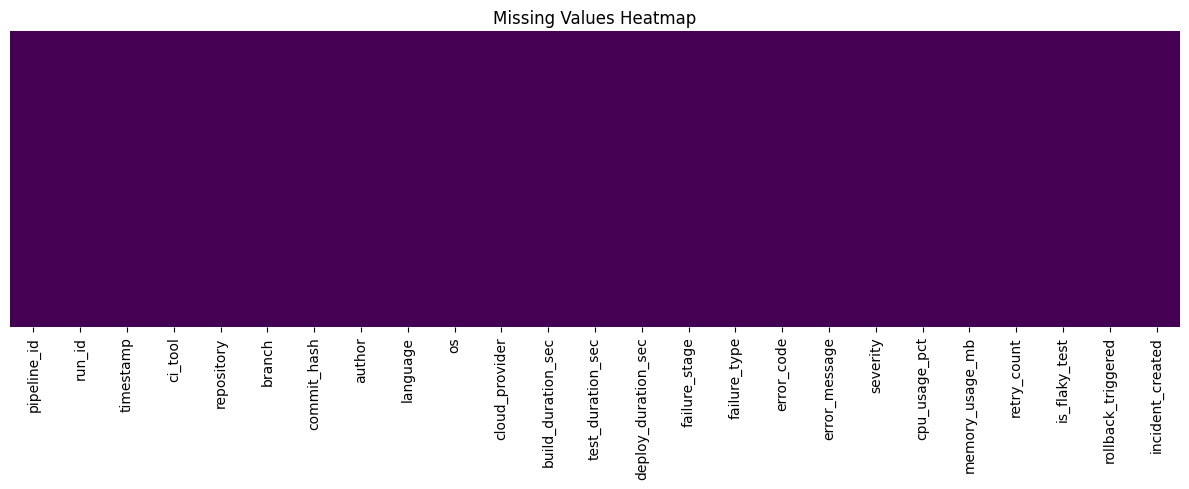

In [37]:
plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Missing Values Heatmap")
plt.tight_layout()
plt.savefig("output/MissingHeatmap.png")
plt.show()

Visualizing the data distribution of numerical columns

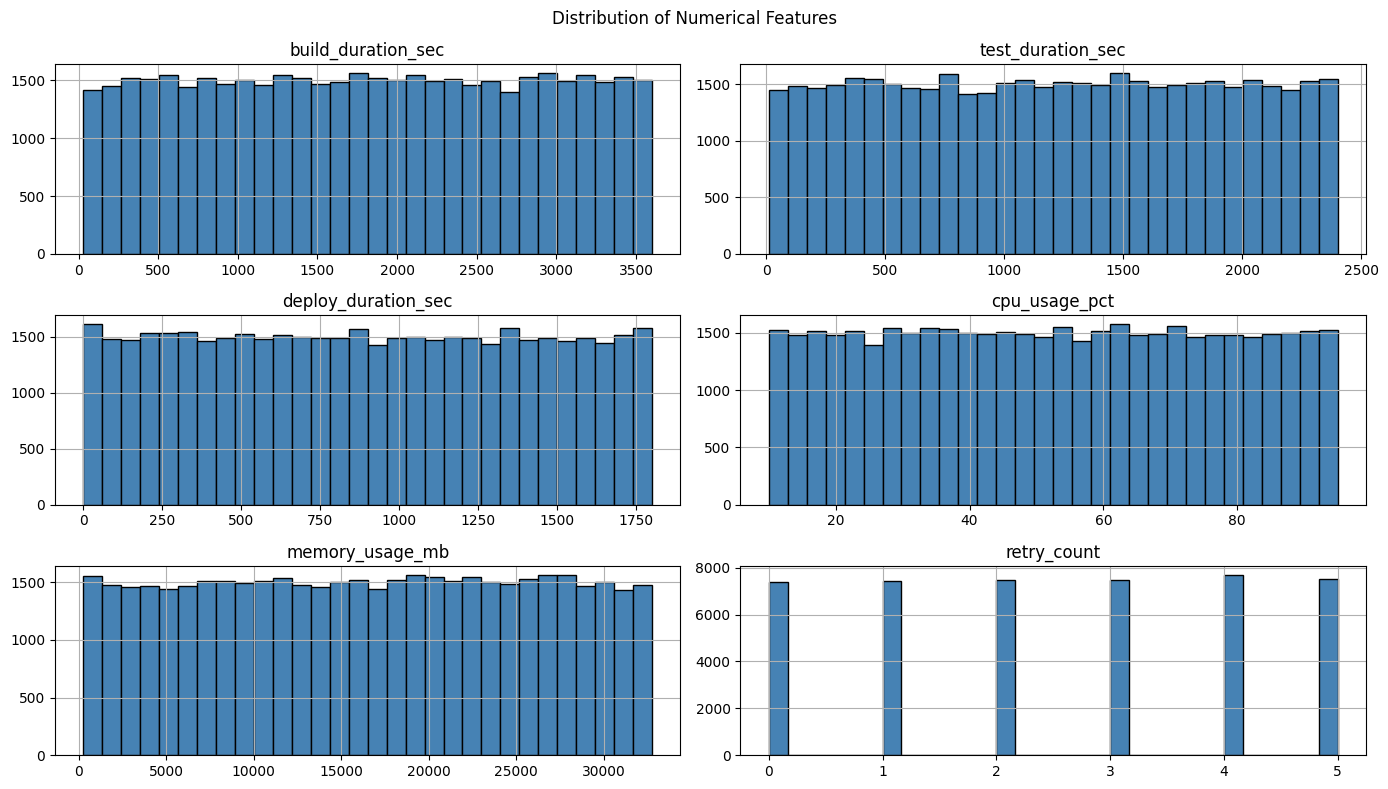

In [38]:
numColumns = ["build_duration_sec", "test_duration_sec", "deploy_duration_sec",
            "cpu_usage_pct", "memory_usage_mb", "retry_count"]

df[numColumns].hist(bins=30, figsize=(14, 8), color="steelblue", edgecolor="black")
plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.savefig("output/NumericalDistributions.png")
plt.show()

Now Checking data distribution of categorical columns

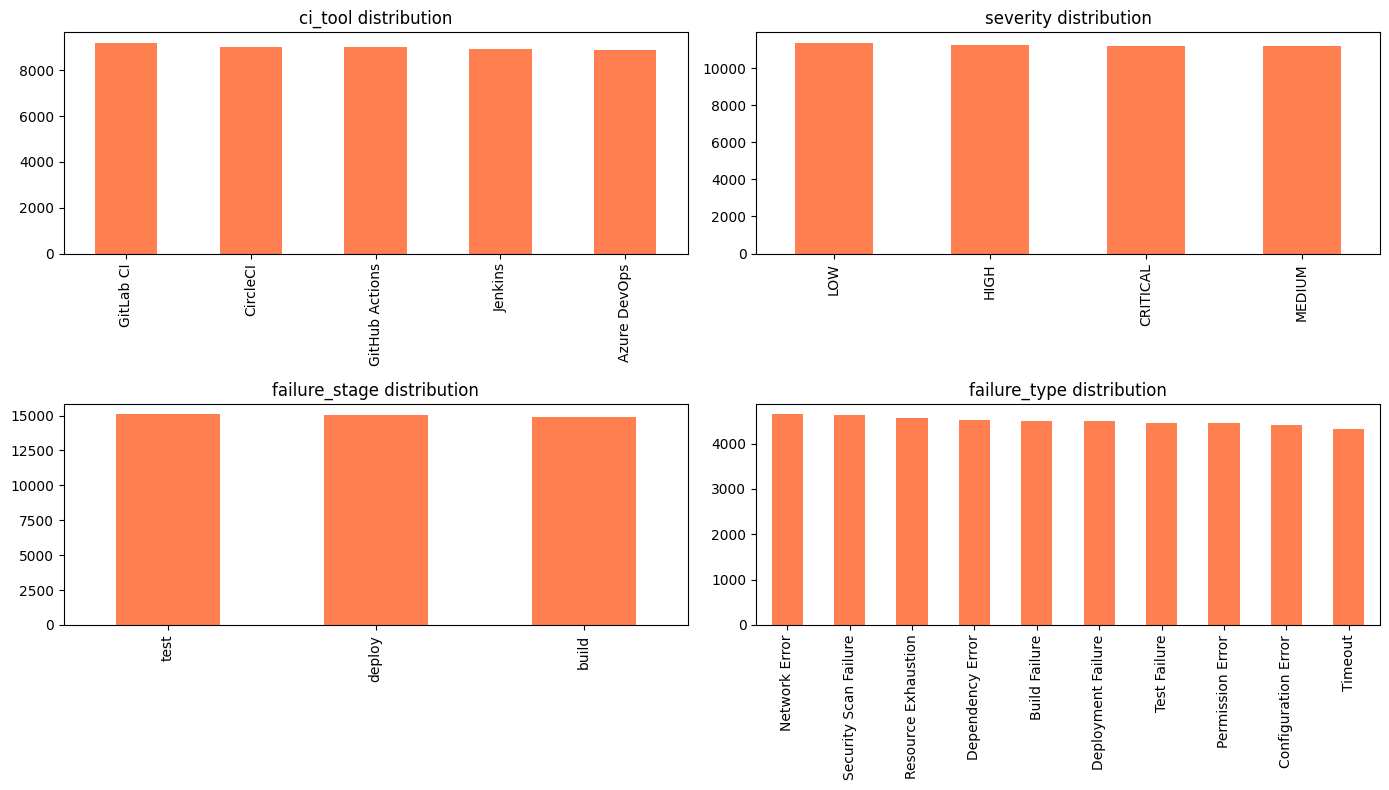

In [39]:
categoricalCols = ["ci_tool", "severity", "failure_stage", "failure_type"]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, col in zip(axes.flatten(), categoricalCols):
    df[col].value_counts().plot(kind="bar", ax=ax, color="coral")
    ax.set_title(f"{col} distribution")
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig("output/CategoricalDistributions.png")
plt.show()

Visualizing outliers in numerical columns using boxplot so that values can be check if they are out of range or not

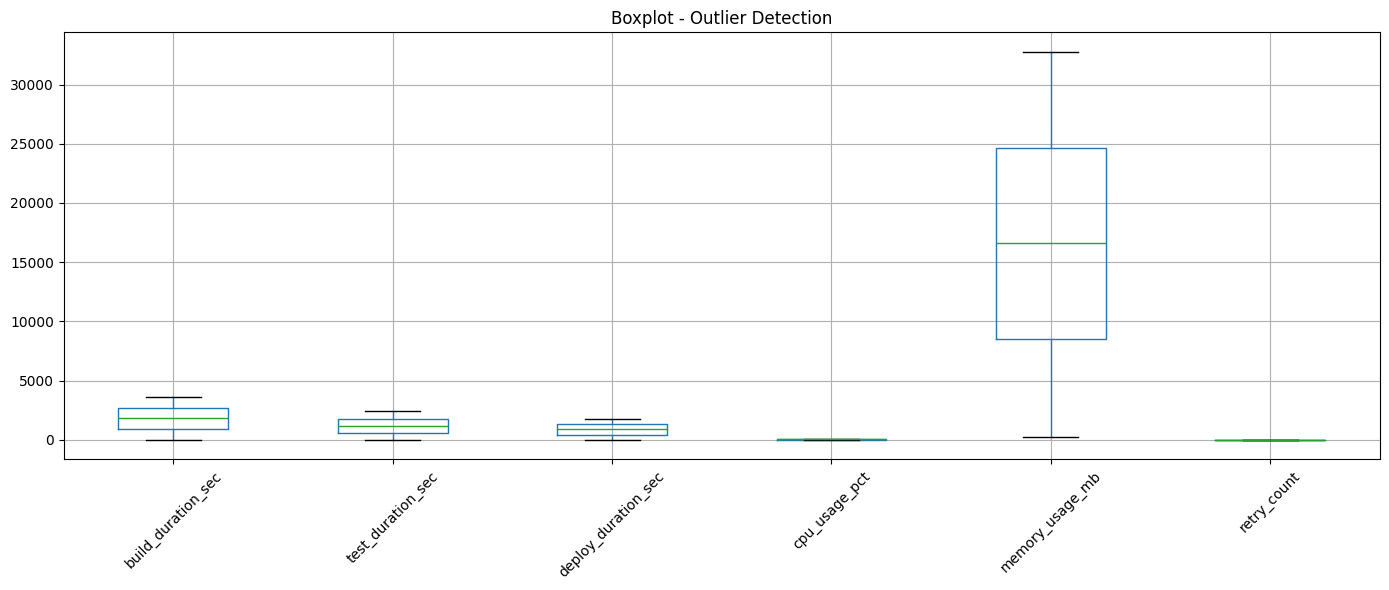

In [40]:
plt.figure(figsize=(14, 6))
df[numColumns].boxplot()
plt.title("Boxplot - Outlier Detection")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("output/boxplots.png")
plt.show()

Finding relationship between columns so to find how much target variable is correlated with other columns

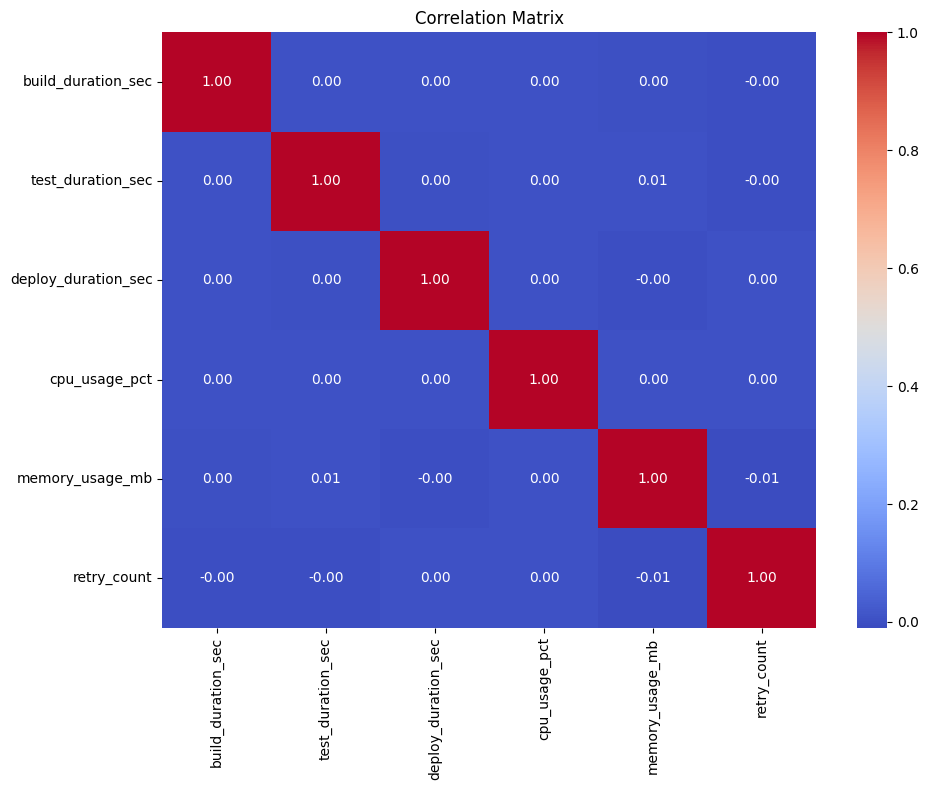

In [41]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[numColumns].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.savefig("output/CorrelationMatrix.png")
plt.show()

Dropping all the unnecessary columns which not contributes in prediction of target column

In [42]:
df.drop(columns=["pipeline_id", "run_id", "commit_hash", "author"], inplace=True)

After dropping, next is to verify columns in a dataset if properly dropped or not

In [43]:
df.head()

,timestamp,ci_tool,repository,branch,language,os,cloud_provider,build_duration_sec,test_duration_sec,deploy_duration_sec,...,failure_type,error_code,error_message,severity,cpu_usage_pct,memory_usage_mb,retry_count,is_flaky_test,rollback_triggered,incident_created
0,2025-12-29T07:58:16.927259,Jenkins,repo_469,release,Python,windows-latest,On-Prem,1996,805,532,...,Security Scan Failure,ERR_621,ERROR: RjyJqtFYmKiXBA5qwUE5HeQgJ2AOHlTqsFEGfE3...,MEDIUM,41.15,3132,3,True,True,True
1,2025-11-23T05:49:16.927259,Jenkins,repo_468,feature-x,Python,ubuntu-latest,AWS,418,1163,386,...,Build Failure,ERR_136,ERROR: 5r2039obpbhM8gNiE2GPONpWhYnkQBqFoM0IhXl...,CRITICAL,31.07,3665,2,True,True,True
2,2026-01-02T05:36:16.927259,Jenkins,repo_360,main,Go,ubuntu-latest,On-Prem,1154,680,290,...,Build Failure,ERR_929,ERROR: g8tprJBHkhLu3r6EtkU5E0Y51Gda8lfG5 4iCOM...,HIGH,27.94,23250,4,False,True,True
3,2025-12-02T02:12:16.927259,Jenkins,repo_47,develop,Python,ubuntu-latest,On-Prem,3176,836,224,...,Resource Exhaustion,ERR_699,ERROR: hqMA49ZWCXsrHsXy81t5pCoPJBer4QpdnJdelM7...,HIGH,56.01,23221,1,False,True,True
4,2025-12-26T17:18:16.927259,GitHub Actions,repo_472,main,NodeJS,ubuntu-latest,GCP,1705,945,1694,...,Security Scan Failure,ERR_201,ERROR: XSxiDN8XrGhYd9legdlv1fCtI9ILHaTM94tucUU...,HIGH,54.63,27558,0,False,False,True


Now Creating a column named as anomaly label by using other columns which contributed in detection of anomalies

In [44]:
df["anomaly_label"] = (
    (df["build_duration_sec"] > df["build_duration_sec"].quantile(0.97)) |
    (df["cpu_usage_pct"] > df["cpu_usage_pct"].quantile(0.97)) |
    (df["memory_usage_mb"] > df["memory_usage_mb"].quantile(0.97)) |
    (df["deploy_duration_sec"] > df["deploy_duration_sec"].quantile(0.97))
).astype(int)

print(df["anomaly_label"].value_counts(normalize=True).round(3))

anomaly_label
0    0.885
1    0.115
Name: proportion, dtype: float64


Creating another column named as total duration sec by adding values from three columns build duration, test duration and deploy duration so to make single column

In [45]:
df["total_duration_sec"] = df["build_duration_sec"] + df["test_duration_sec"] + df["deploy_duration_sec"]

Next is to encode categorical columns so that can be use to model properly

In [46]:
from sklearn.preprocessing import LabelEncoder
catergoricalCols = ["ci_tool", "branch", "language", "os", "cloud_provider",
            "failure_stage", "failure_type", "error_code", "severity"]
le = LabelEncoder()
for col in catergoricalCols:
    df[col] = le.fit_transform(df[col].astype(str))

In [47]:
df.head()

,timestamp,ci_tool,repository,branch,language,os,cloud_provider,build_duration_sec,test_duration_sec,deploy_duration_sec,...,error_message,severity,cpu_usage_pct,memory_usage_mb,retry_count,is_flaky_test,rollback_triggered,incident_created,anomaly_label,total_duration_sec
0,2025-12-29T07:58:16.927259,4,repo_469,3,4,2,3,1996,805,532,...,ERROR: RjyJqtFYmKiXBA5qwUE5HeQgJ2AOHlTqsFEGfE3...,3,41.15,3132,3,True,True,True,0,3333
1,2025-11-23T05:49:16.927259,4,repo_468,1,4,1,0,418,1163,386,...,ERROR: 5r2039obpbhM8gNiE2GPONpWhYnkQBqFoM0IhXl...,0,31.07,3665,2,True,True,True,0,1967
2,2026-01-02T05:36:16.927259,4,repo_360,2,1,1,3,1154,680,290,...,ERROR: g8tprJBHkhLu3r6EtkU5E0Y51Gda8lfG5 4iCOM...,1,27.94,23250,4,False,True,True,0,2124
3,2025-12-02T02:12:16.927259,4,repo_47,0,4,1,3,3176,836,224,...,ERROR: hqMA49ZWCXsrHsXy81t5pCoPJBer4QpdnJdelM7...,1,56.01,23221,1,False,True,True,0,4236
4,2025-12-26T17:18:16.927259,2,repo_472,2,3,1,2,1705,945,1694,...,ERROR: XSxiDN8XrGhYd9legdlv1fCtI9ILHaTM94tucUU...,1,54.63,27558,0,False,False,True,0,4344


Instead of dropping these important columning filling blanks places with none value

In [48]:
df["error_message"].fillna("none", inplace=True)
df["failure_stage"].fillna("none", inplace=True)
df["failure_type"].fillna("none", inplace=True)

C:\Users\DELL\AppData\Local\Temp\ipykernel_22424\135802859.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df["error_message"].fillna("none", inplace=True)
C:\Users\DELL\AppData\Local\Temp\ipykernel_22424\135802859.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment usi

0        7
1        0
2        0
3        6
4        7
        ..
44995    9
44996    0
44997    2
44998    0
44999    8
Name: failure_type, Length: 45000, dtype: int64

Filling other numerical columns with their median values

In [49]:
for col in ["build_duration_sec", "test_duration_sec", "deploy_duration_sec",
            "cpu_usage_pct", "memory_usage_mb"]:
    df[col].fillna(df[col].median(), inplace=True)

C:\Users\DELL\AppData\Local\Temp\ipykernel_22424\2897485267.py:3: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df[col].fillna(df[col].median(), inplace=True)
C:\Users\DELL\AppData\Local\Temp\ipykernel_22424\2897485267.py:3: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment usi

Lets drop duplicate values so that model can be properly implement

In [50]:
print(f"Duplicates before: {df.duplicated().sum()}")
df.drop_duplicates(inplace=True)
print(f"Duplicates after: {df.duplicated().sum()}")

Duplicates before: 0
Duplicates after: 0


Now after creating new columns, lets see if there is any null values in it

In [51]:
print(df.isnull().sum())  
print(df.shape)

timestamp              0
ci_tool                0
repository             0
branch                 0
language               0
os                     0
cloud_provider         0
build_duration_sec     0
test_duration_sec      0
deploy_duration_sec    0
failure_stage          0
failure_type           0
error_code             0
error_message          0
severity               0
cpu_usage_pct          0
memory_usage_mb        0
retry_count            0
is_flaky_test          0
rollback_triggered     0
incident_created       0
anomaly_label          0
total_duration_sec     0
dtype: int64
(45000, 23)


Now save the cleaned dataset with named preprocessdata.csv

In [ ]:
df.to_csv("data/PreprocessData.csv", index=False)
print("Cleaned dataset saved.")

Cleaned dataset saved.


Now we need to select features which can be use to further creation of model

In [53]:
features = [
    "build_duration_sec", "test_duration_sec", "deploy_duration_sec",
    "cpu_usage_pct", "memory_usage_mb",
    "ci_tool", "language", "os",
    "cloud_provider", "is_flaky_test"
]

Now seperating features and target variable y as anomaly label

In [54]:
X = df[features]
y = df["anomaly_label"]

Now splitting those features and target variable in test set and train set so that model can be properly validated later

In [55]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Train size: {X_train.shape}, Test size: {X_test.shape}")

Train size: (36000, 10), Test size: (9000, 10)


Now we can properly import libraries necessary to create a prediciton model

In [56]:
import pandas as pd
import numpy as np
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, f1_score, precision_score, recall_score

Now its time to build models and our first model will be Isolation forest model

In [57]:
iso = IsolationForest(
    contamination=0.05,
    n_estimators=300,
    max_features=0.8,
    random_state=42
)
iso.fit(X_train)
iso_preds = [1 if p == -1 else 0 for p in iso.predict(X_test)]
iso_scores = iso.decision_function(X_test) * -1


print("Isolation Forest")
print(classification_report(y_test, iso_preds))
print("ROC-AUC:", roc_auc_score(y_test, iso_scores))

Isolation Forest
              precision    recall  f1-score   support

           0       0.90      0.96      0.93      7998
           1       0.34      0.16      0.22      1002

    accuracy                           0.87      9000
   macro avg       0.62      0.56      0.57      9000
weighted avg       0.84      0.87      0.85      9000

ROC-AUC: 0.7394800296880606


Now we can create xgboost model

In [58]:
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
xgb = XGBClassifier(
    n_estimators=100, max_depth=4,
    learning_rate=0.1, subsample=0.8,
    scale_pos_weight=neg/pos,
    random_state=42, eval_metric="logloss"
)
xgb.fit(X_train, y_train)
xgb_preds = xgb.predict(X_test)
xgb_proba = xgb.predict_proba(X_test)[:, 1]
print("XGBoost")
print(classification_report(y_test, xgb_preds))
print("ROC-AUC:", roc_auc_score(y_test, xgb_proba))

XGBoost
              precision    recall  f1-score   support

           0       1.00      0.99      1.00      7998
           1       0.95      1.00      0.97      1002

    accuracy                           0.99      9000
   macro avg       0.97      0.99      0.98      9000
weighted avg       0.99      0.99      0.99      9000

ROC-AUC: 0.9997568004775644


Now we need to dump the model because it is properly created

In [59]:
import joblib

joblib.dump(iso, "models/isolation_forest.pkl")
joblib.dump(xgb, "models/xgboost.pkl")

['models/xgboost.pkl']

Now saving all features in csv format

In [60]:
featureList = pd.Series(features)
featureList.to_csv("models/features.csv", index=False)

Now we need to see how our model is correctly predicted using confusion matrix graph 

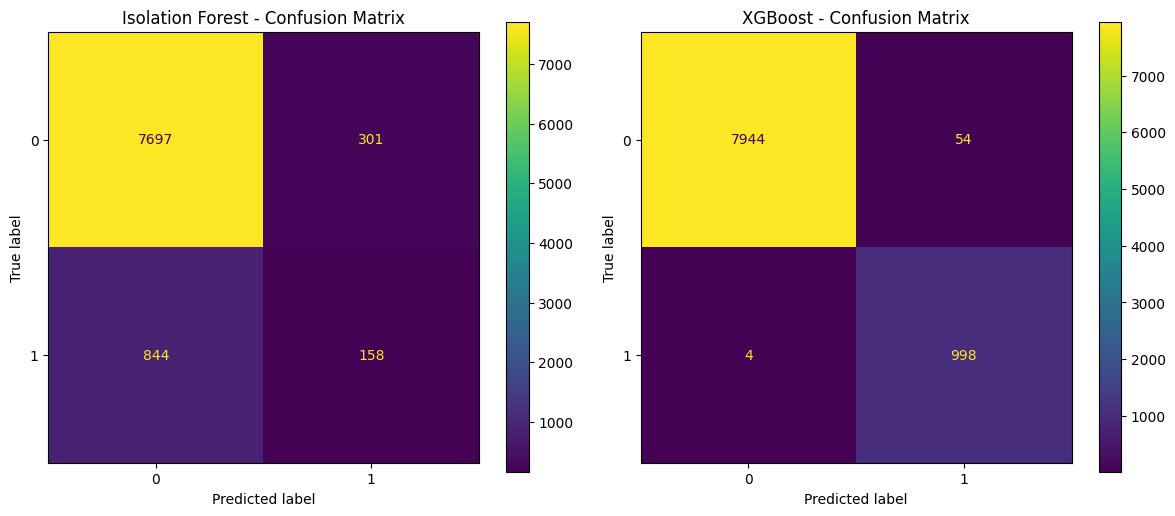

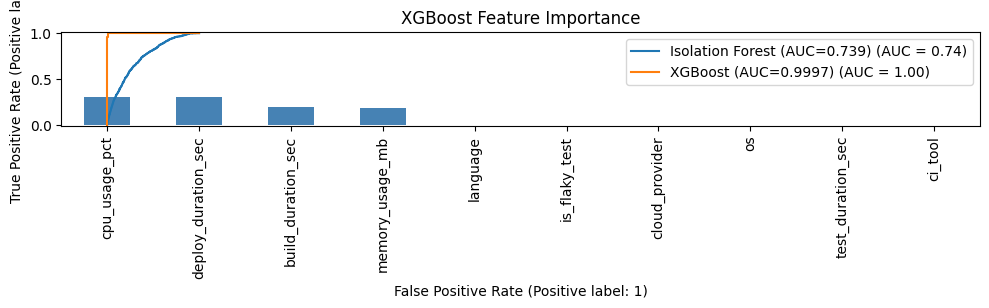

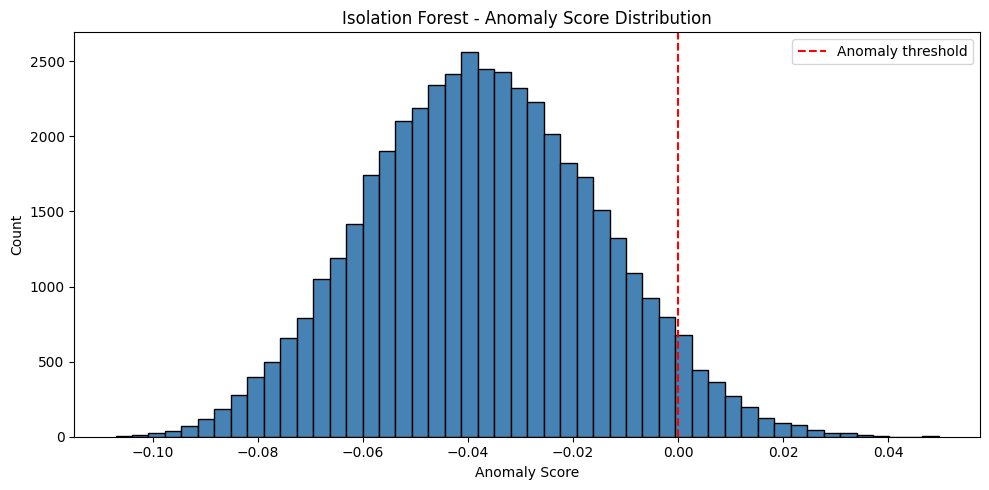

In [61]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, iso_preds)).plot(ax=axes[0])
axes[0].set_title("Isolation Forest - Confusion Matrix")
ConfusionMatrixDisplay(confusion_matrix(y_test, xgb_preds)).plot(ax=axes[1])
axes[1].set_title("XGBoost - Confusion Matrix")
plt.tight_layout()
plt.savefig("output/ConfusionMatrices.png", dpi=150)

fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_predictions(y_test, iso_scores, ax=ax, name="Isolation Forest (AUC=0.739)")
RocCurveDisplay.from_predictions(y_test, xgb_proba, ax=ax, name="XGBoost (AUC=0.9997)")
plt.title("ROC Curve Comparison")
plt.tight_layout()
plt.savefig("output/RocCurve.png", dpi=150)

pd.Series(xgb.feature_importances_, index=features).sort_values(ascending=False).plot(
    kind="bar", figsize=(10, 5), color="steelblue", title="XGBoost Feature Importance"
)
plt.tight_layout()
plt.savefig("output/FeatureImportance.png", dpi=150)

all_scores = iso.decision_function(X) * -1
plt.figure(figsize=(10, 5))
plt.hist(all_scores, bins=50, color="steelblue", edgecolor="black")
plt.axvline(x=0, color="red", linestyle="--", label="Anomaly threshold")
plt.title("Isolation Forest - Anomaly Score Distribution")
plt.xlabel("Anomaly Score")
plt.ylabel("Count")
plt.legend()
plt.tight_layout()
plt.savefig("output/AnomalyScores.png", dpi=150)


Now, we need to save thresholds values in json format

In [62]:
import json
thresholds = {
    "build_duration_sec": float(df["build_duration_sec"].quantile(0.97)),
    "test_duration_sec": float(df["test_duration_sec"].quantile(0.97)),
    "deploy_duration_sec": float(df["deploy_duration_sec"].quantile(0.97)),
    "cpu_usage_pct": float(df["cpu_usage_pct"].quantile(0.97)),
    "memory_usage_mb": float(df["memory_usage_mb"].quantile(0.97)),
}


with open("models/thresholds.json", "w") as f:
    json.dump(thresholds, f, indent=2)

print("Saved thresholds:")
print(json.dumps(thresholds, indent=2))

Saved thresholds:
{
  "build_duration_sec": 3494.0,
  "test_duration_sec": 2330.0,
  "deploy_duration_sec": 1749.0,
  "cpu_usage_pct": 92.45,
  "memory_usage_mb": 31775.059999999998
}
